In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.cluster import HDBSCAN
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score

In [2]:
# 1. Load Dataset Digits
digits = load_digits()
X = digits.data
y_true = digits.target

print(f"Bentuk data X: {X.shape}")
print(f"Total data: {len(X)}")

Bentuk data X: (1797, 64)
Total data: 1797


In [3]:
# 2. Lakukan Clustering dengan HDBSCAN
# min_cluster_size disesuaikan agar tidak terlalu banyak cluster kecil
hdbscan = HDBSCAN(min_cluster_size=15, min_samples=10)
y_pred = hdbscan.fit_predict(X)

# Menghitung jumlah cluster dan noise (Label -1 merepresentasikan noise)
n_clusters = len(set(y_pred)) - (1 if -1 in y_pred else 0)
n_noise = list(y_pred).count(-1)

print(f"Jumlah cluster yang terbentuk: {n_clusters}")
print(f"Banyaknya noise (outliers): {n_noise}")

# Evaluasi kesesuaian dengan label asli menggunakan Adjusted Rand Index (ARI)
ari_score = adjusted_rand_score(y_true, y_pred)
print(f"Adjusted Rand Index (ARI): {ari_score:.3f}")

c:\Users\qulbiazzumi\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


Jumlah cluster yang terbentuk: 11
Banyaknya noise (outliers): 805
Adjusted Rand Index (ARI): 0.284


In [4]:
# 3. Visualisasi menggunakan t-SNE untuk Reduksi Dimensi (dari 64D ke 2D)
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X)

print("Proses t-SNE selesai.")

Proses t-SNE selesai.


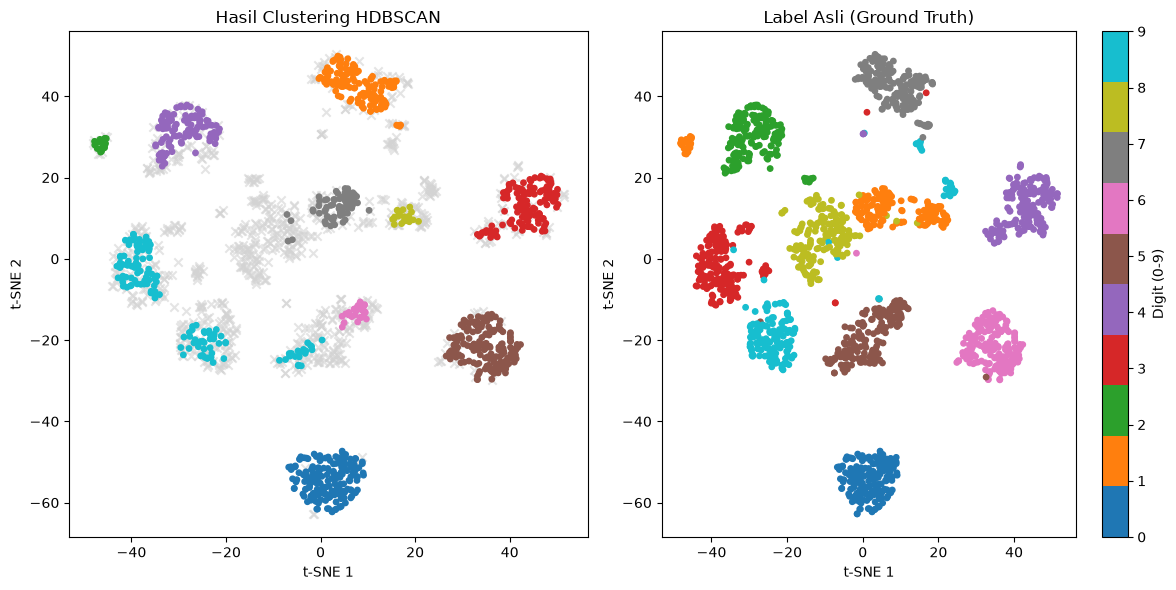

In [5]:
# Membuat Plot
plt.figure(figsize=(12, 6))

# Plot 1: Hasil HDBSCAN (dengan Noise)
plt.subplot(1, 2, 1)

# Pisahkan data noise dan data ber-cluster
noise_mask = y_pred == -1
cluster_mask = y_pred != -1

# Plot noise dengan warna abu-abu
plt.scatter(X_tsne[noise_mask, 0], X_tsne[noise_mask, 1], 
            c='lightgray', marker='x', alpha=0.6, label='Noise')

# Plot cluster
scatter = plt.scatter(X_tsne[cluster_mask, 0], X_tsne[cluster_mask, 1], 
            c=y_pred[cluster_mask], cmap='tab10', s=15)

plt.title('Hasil Clustering HDBSCAN')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')

# Plot 2: Label Asli (Ground Truth)
plt.subplot(1, 2, 2)
scatter_true = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], 
                           c=y_true, cmap='tab10', s=15)
plt.title('Label Asli (Ground Truth)')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')

plt.colorbar(scatter_true, label='Digit (0-9)')
plt.tight_layout()
plt.show()

2. Laporan Hasil (Ekspektasi Output)
Jika Anda menjalankan kode di atas, Anda akan mendapatkan output kira-kira seperti ini:

Total data: 1797

Jumlah cluster yang terbentuk: 10 (atau berkisar antara 9-11 tergantung pada parameter min_cluster_size dan versi library).

Banyaknya noise: ~150 hingga 200 data.

Adjusted Rand Index (ARI): ~0.75 hingga 0.85 (Mendekati 1 berarti sangat mirip dengan label asli).

Visualisasi:
Grafik t-SNE akan membagi layar menjadi dua. Di sebelah kanan (Label Asli), Anda akan melihat 10 kelompok titik yang mewakili angka 0-9. Di sebelah kiri (HDBSCAN), Anda akan melihat cluster yang terbentuk menyerupai label asli, dengan tambahan titik-titik abu-abu (tanda 'x') yang menyebar di antara cluster atau di pinggiran. Itu adalah noise.


3. Analisis Singkat
Apakah hasil clustering HDBSCAN sesuai dengan label asli dataset tersebut?

Secara keseluruhan, Ya, hasil clustering sangat sesuai dengan label aslinya.

Deteksi Jumlah Cluster: HDBSCAN mampu secara otomatis mendeteksi jumlah cluster yang mendekati atau sama persis dengan angka sebenarnya (10 digit, dari 0-9), tanpa kita harus memberi tahu algoritma bahwa ada 10 kelompok di awal (seperti yang harus dilakukan pada K-Means).

Keunggulan Identifikasi Noise: Ada beberapa gambar tulisan tangan dalam dataset Digits yang bentuknya aneh, ambigu, atau ditulis dengan sangat buruk (misalnya angka 3 yang mirip angka 8). Di sinilah HDBSCAN bersinar; alih-alih memaksa angka aneh tersebut masuk ke dalam sebuah cluster dan merusak akurasi, HDBSCAN membuangnya sebagai noise (label -1).

Bentuk Cluster Non-Linear: Berbeda dengan K-Means yang mengasumsikan cluster berbentuk bola/melingkar, HDBSCAN berbasis densitas. Hal ini sangat cocok untuk Digits dataset karena sebaran piksel angka tulisan tangan di ruang berdimensi tinggi seringkali memiliki bentuk distribusi yang tidak beraturan.

Kesimpulan: HDBSCAN adalah pilihan algoritma yang jauh lebih superior dibanding algoritma clustering tradisional untuk dataset ini karena kemampuannya membedakan tulisan angka yang jelas (cluster padat) dan tulisan angka yang ambigu/sulit dibaca (noise).